In [1]:
from pathlib import Path
import os
# The project folder is the folder that contains data/, notebooks/, results/ ...
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROJECT_DIR = Path(os.environ.get('PROJECT_DIR', PROJECT_DIR))
print('Project folder:', PROJECT_DIR)
assert (PROJECT_DIR / 'data').exists(), 'Project folder not found - open this notebook from the notebooks folder of the project (see your Steps file)'


Project folder: /Users/pranav/Documents/game-chat-toxicity-ml 


In [2]:
import re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix
 
SEED = 42
OUT_DIR   = PROJECT_DIR / 'data' / 'processed'
RESP_DIR  = PROJECT_DIR / 'data' / 'responses'
BATCH_DIR = PROJECT_DIR / 'data' / 'batches'
AUDIT_DIR = PROJECT_DIR / 'data' / 'audit'
LAB_DIR   = PROJECT_DIR / 'data' / 'labelled'
RES_DIR   = PROJECT_DIR / 'results'
for d in (RESP_DIR, AUDIT_DIR, LAB_DIR, RES_DIR / 'figures'): d.mkdir(parents=True, exist_ok=True)
 
ALLOW_MISSING = False     # set True only if you accept that a few messages stay unlabelled
N_BATCHES_LABELLED = 20           # FAST MODE: only batches 001-020 (2,000 messages) are labelled. Use 34 if you labelled all batches.
AUDIT_N = 100                     # number of messages you re-label by hand to check the AI labels


In [3]:
cand = pd.read_csv(OUT_DIR / 'candidates_to_label.csv')
cand = cand[cand.id <= N_BATCHES_LABELLED * 100].copy()      # the candidates are shuffled, so any first batches are a fair sample
print('messages in scope:', len(cand))
pat = re.compile(r'^\s*[\[\(]?(\d+)[\]\)]?\s*[,:=\-\.\)]\s*([012xX])\b')
rows = []
for f in sorted(RESP_DIR.glob('*.txt')):          # later files (redo_*) override earlier ones
    for line in f.read_text(encoding='utf-8', errors='ignore').splitlines():
        m = pat.match(line)
        if m: rows.append((int(m.group(1)), m.group(2).upper(), f.name))
resp = pd.DataFrame(rows, columns=['id', 'llm_label', 'file'])
print('answer lines read:', len(resp), 'from', resp.file.nunique(), 'files')
resp = resp[resp.id.isin(cand.id)].drop_duplicates('id', keep='last')
 
lab = cand.merge(resp[['id', 'llm_label']], on='id', how='left')
missing = lab[lab.llm_label.isna()]
print('labelled:', lab.llm_label.notna().sum(), '| missing:', len(missing))
if len(missing):
    PROMPT_TXT = (OUT_DIR / 'labelling_prompt.txt').read_text(encoding='utf-8')
    for f in BATCH_DIR.glob('redo_*.txt'): f.unlink()
    for k in range(0, len(missing), 100):
        chunk = missing.iloc[k:k + 100]
        body = PROMPT_TXT + '\n\nMESSAGES:\n' + '\n'.join(f'{r.id}: {r.text}' for r in chunk.itertuples())
        (BATCH_DIR / f'redo_{k // 100 + 1:03d}.txt').write_text(body, encoding='utf-8')
    print('-> Created redo batches in data/batches/ (redo_001.txt ...). Paste them into the AI, save replies as data/responses/redo_001.txt etc., then re-run this cell.')
assert len(missing) == 0 or ALLOW_MISSING, 'Some messages are still unlabelled - see the redo batches above.'
lab = lab[lab.llm_label.notna()].copy()
print(lab.llm_label.value_counts().to_dict())
print(pd.crosstab(lab.group, lab.llm_label))



messages in scope: 2000
answer lines read: 2000 from 20 files
labelled: 2000 | missing: 0
{'0': 1113, '1': 728, '2': 141, 'X': 18}
llm_label     0    1    2   X
group                        
lexicon      18  432   14   1
random      868   49    2  13
strong        2  232  122   1
toxic_case  225   15    3   3


In [4]:
lab.to_csv(OUT_DIR / 'labelled_by_llm.csv', index=False, encoding='utf-8')
usable = lab[lab.llm_label != 'X'].copy()
print('skipped as X (non-English / meaningless):', (lab.llm_label == 'X').sum(), '| usable:', len(usable))


skipped as X (non-English / meaningless): 18 | usable: 1982


In [5]:
p_audit = AUDIT_DIR / 'audit_pranav.csv'
if not p_audit.exists():
    per = AUDIT_N // 3
    picked = []
    for lbl in ['0', '1', '2']:                          # roughly equal numbers of each AI label
        sub = usable[usable.llm_label == lbl]
        picked.append(sub.sample(min(per, len(sub)), random_state=SEED))
    picked = pd.concat(picked)
    if len(picked) < AUDIT_N:
        rest = usable.drop(picked.index)
        picked = pd.concat([picked, rest.sample(AUDIT_N - len(picked), random_state=SEED)])
    sheet = picked.sample(frac=1, random_state=SEED)[['id', 'text']].copy()
    sheet['my_label'] = ''
    sheet.to_csv(p_audit, index=False, encoding='utf-8-sig')
    print('Audit sheet created:', p_audit, '-> fill the my_label column, then continue with Part C.')
else:
    print('Audit sheet already exists.')


Audit sheet created: /Users/pranav/Documents/game-chat-toxicity-ml /data/audit/audit_pranav.csv -> fill the my_label column, then continue with Part C.


In [6]:
a = pd.read_csv(p_audit, encoding='utf-8-sig', dtype={'my_label': str})
a['my_label'] = a['my_label'].fillna('').astype(str).str.strip().str.upper().str.replace('.0', '', regex=False)
done = a[a.my_label.isin(['0', '1', '2', 'X'])][['id', 'my_label']].rename(columns={'my_label': 'human'})
print(f'audit sheet: {len(done)} / {len(a)} rows filled')
 
quality = {}
final = usable[['id', 'text', 'source', 'llm_label']].copy()
final['label'] = final['llm_label']
final['label_source'] = 'llm'
 
if len(done) >= 0.9 * len(a):
    h = done.merge(usable[['id', 'llm_label']], on='id', how='left')
    h = h[h.human != 'X']
    quality['llm_vs_human_n'] = int(len(h))
    quality['llm_vs_human_accuracy'] = round(float(accuracy_score(h.human, h.llm_label)), 3)
    quality['llm_vs_human_kappa'] = round(float(cohen_kappa_score(h.human, h.llm_label)), 3)
    quality['llm_precision_per_class'] = {c: round(float((h[h.llm_label == c].human == c).mean()), 3) for c in ['0', '1', '2'] if (h.llm_label == c).any()}
    print(json.dumps(quality, indent=2))
    print('Confusion (rows = AI label, columns = human label):')
    print(pd.crosstab(h.llm_label, h.human))
    # apply corrections (human label wins; X = drop the message)
    hmap = done.set_index('id').human.to_dict()
    final['label'] = [hmap.get(i, l) for i, l in zip(final.id, final.label)]
    final['label_source'] = ['human' if i in hmap else 'llm' for i in final.id]
    quality['corrected_by_human'] = int((final.label != final.llm_label).sum())
else:
    print('WARNING: audit sheet not (fully) filled - using AI labels only. Do not submit like this.')
 
final = final[final.label.isin(['0', '1', '2'])].copy()
final['label'] = final.label.astype(int)
final[['id', 'text', 'source', 'label', 'label_source']].to_csv(LAB_DIR / 'labelled.csv', index=False, encoding='utf-8')
print('final labelled messages:', len(final), final.label.value_counts().sort_index().to_dict())


audit sheet: 100 / 100 rows filled
{
  "llm_vs_human_n": 97,
  "llm_vs_human_accuracy": 0.763,
  "llm_vs_human_kappa": 0.643,
  "llm_precision_per_class": {
    "0": 0.767,
    "1": 0.706,
    "2": 0.818
  }
}
Confusion (rows = AI label, columns = human label):
human       0   1   2
llm_label            
0          23   6   1
1           5  24   5
2           0   6  27
final labelled messages: 1979 {0: 1108, 1: 730, 2: 141}


train: 1583 | test: 396


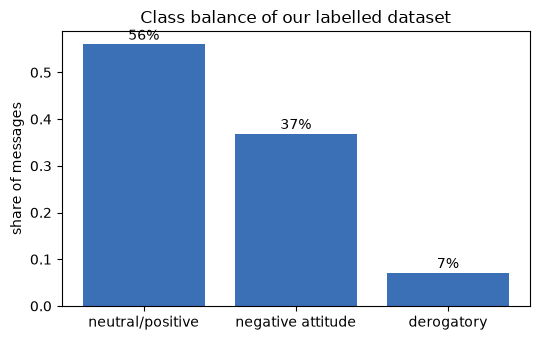

In [7]:
train, test = train_test_split(final[['id', 'text', 'source', 'label']], test_size=0.2, stratify=final.label, random_state=SEED)
train.to_csv(LAB_DIR / 'train.csv', index=False, encoding='utf-8')
test.to_csv(LAB_DIR / 'test.csv', index=False, encoding='utf-8')
print('train:', len(train), '| test:', len(test))
 
names = ['neutral/positive', 'negative attitude', 'derogatory']
share = final.label.value_counts(normalize=True).sort_index()
plt.figure(figsize=(5.5, 3.5))
plt.bar(names, share.values, color='#3b6fb6')
plt.ylabel('share of messages'); plt.title('Class balance of our labelled dataset')
for i, v in enumerate(share.values): plt.text(i, v + 0.01, f'{v:.0%}', ha='center')
plt.tight_layout(); plt.savefig(RES_DIR / 'figures' / 'class_balance.png', dpi=150); plt.show()
 
quality.update({'total_labelled': int(len(final)), 'train': int(len(train)), 'test': int(len(test)),
                'class_share': {names[i]: round(float(v), 3) for i, v in share.items()}})
json.dump(quality, open(RES_DIR / 'label_quality.json', 'w'), indent=2)
